In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import GammaRegressor
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [ ]:
# loading the data from csv file to Pandas DataFrame
big_mart_data = pd.read_csv('/content/Train.csv')
test_data = pd.read_csv('/content/Test.csv')

# first 5 rows of the dataframe
big_mart_data.head()

# number of data points & number of features
big_mart_data.shape

# getting some information about thye dataset
big_mart_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [ ]:
# checking for missing values
big_mart_data.isnull().sum()

# Item_Weight: a product has ONE fixed weight, so instead of the mean we copy the
# weight of the same product (Item_Identifier) from the outlets that did report it.
# Train and test are combined for the lookup, because a weight missing in one file
# may be present in the other.
all_items = pd.concat([big_mart_data, test_data], ignore_index=True)
weight_lookup = all_items.groupby('Item_Identifier')['Item_Weight'].first()   # first() skips NaN

# fallback (not needed on this dataset): median weight of the same Item_Type
type_median = all_items.groupby('Item_Type')['Item_Weight'].median()

def fill_weight(df):
    df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Identifier'].map(weight_lookup))
    df['Item_Weight'] = df['Item_Weight'].fillna(df['Item_Type'].map(type_median))
    return df

print('Missing weights before:', big_mart_data['Item_Weight'].isnull().sum(), 'train /', test_data['Item_Weight'].isnull().sum(), 'test')
big_mart_data = fill_weight(big_mart_data)
test_data = fill_weight(test_data)
print('Missing weights after :', big_mart_data['Item_Weight'].isnull().sum(), 'train /', test_data['Item_Weight'].isnull().sum(), 'test')

Missing weights before: 1463 train / 976 test
Missing weights after : 0 train / 0 test


In [ ]:

# mode of "Outlet_Size" column
big_mart_data['Outlet_Size'].mode()

# filling the missing values in "Outlet_Size" column with Mode
mode_of_Outlet_size = big_mart_data.pivot_table(values='Outlet_Size', columns='Outlet_Type', aggfunc=(lambda x: x.mode()[0]))

print(mode_of_Outlet_size)

miss_values = big_mart_data['Outlet_Size'].isnull()

print(miss_values)

big_mart_data.loc[miss_values, 'Outlet_Size'] = big_mart_data.loc[miss_values,'Outlet_Type'].apply(lambda x: mode_of_Outlet_size[x])

# checking for missing values
big_mart_data.isnull().sum()


Outlet_Type Grocery Store Supermarket Type1 Supermarket Type2  \
Outlet_Size         Small             Small            Medium   

Outlet_Type Supermarket Type3  
Outlet_Size            Medium  
0       False
1       False
2       False
3        True
4       False
        ...  
8518    False
8519     True
8520    False
8521    False
8522    False
Name: Outlet_Size, Length: 8523, dtype: bool


,0
Item_Identifier,0
Item_Weight,0
Item_Fat_Content,0
Item_Visibility,0
Item_Type,0
Item_MRP,0
Outlet_Identifier,0
Outlet_Establishment_Year,0
Outlet_Size,0
Outlet_Location_Type,0


In [ ]:
"""Data Analysis"""
 # will give statistical measures about the data
big_mart_data.describe()


,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,8523.000000,8523.000000,8523.000000,8523.000000,8523.000000
mean,12.873623,0.066132,140.992782,1997.831867,2181.288914
std,4.645893,0.051598,62.275067,8.371760,1706.499616
min,4.555000,0.000000,31.290000,1985.000000,33.290000
25%,8.785000,0.026989,93.826500,1987.000000,834.247400
50%,12.600000,0.053931,143.012800,1999.000000,1794.331000
75%,16.850000,0.094585,185.643700,2004.000000,3101.296400
max,21.350000,0.328391,266.888400,2009.000000,13086.964800


In [ ]:
sns.set()

/tmp/ipykernel_10732/1330319193.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(big_mart_data['Item_Weight'])


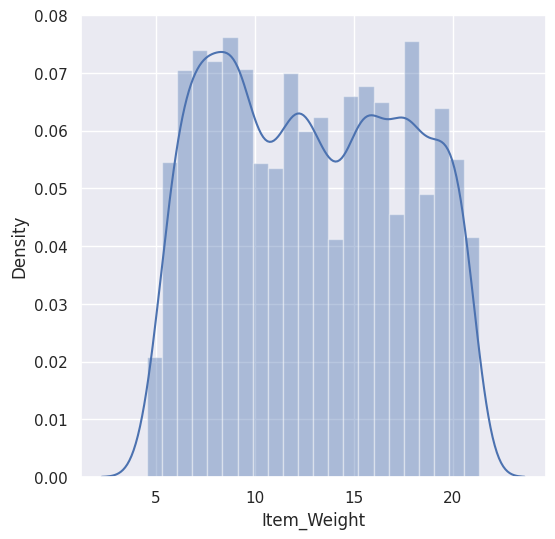

In [ ]:
# Item_Weight distribution
plt.figure(figsize=(6,6))
sns.distplot(big_mart_data['Item_Weight'])
plt.show()

/tmp/ipykernel_10732/193435663.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(big_mart_data['Item_Visibility'])


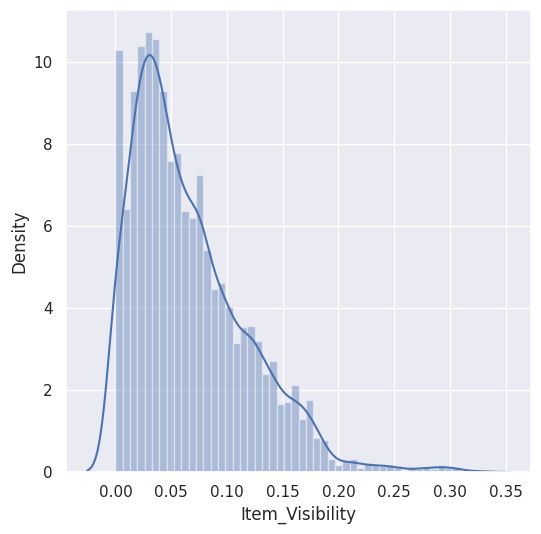

In [ ]:
# Item Visibility distribution
plt.figure(figsize=(6,6))
sns.distplot(big_mart_data['Item_Visibility'])
plt.show()

/tmp/ipykernel_10732/1610987680.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(big_mart_data['Item_MRP'])


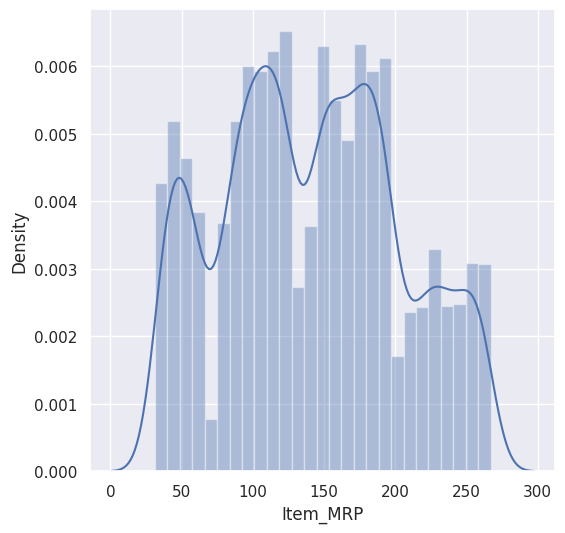

In [ ]:
# Item MRP distribution
plt.figure(figsize=(6,6))
sns.distplot(big_mart_data['Item_MRP'])
plt.show()

/tmp/ipykernel_10732/1323853436.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(big_mart_data['Item_Outlet_Sales'])


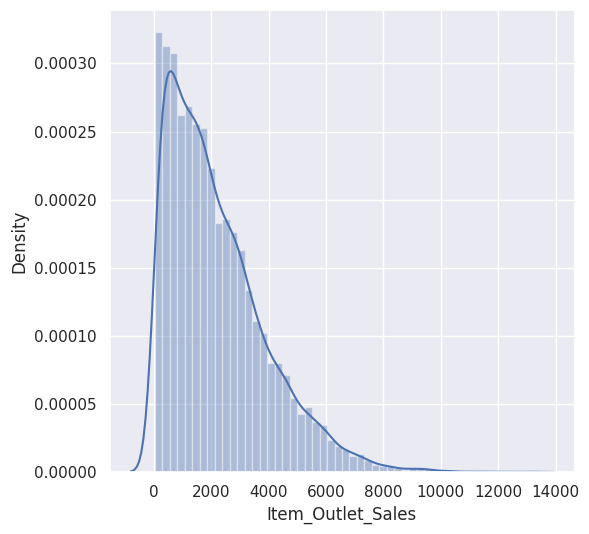

In [ ]:
# Item_Outlet_Sales distribution
plt.figure(figsize=(6,6))
sns.distplot(big_mart_data['Item_Outlet_Sales'])
plt.show()

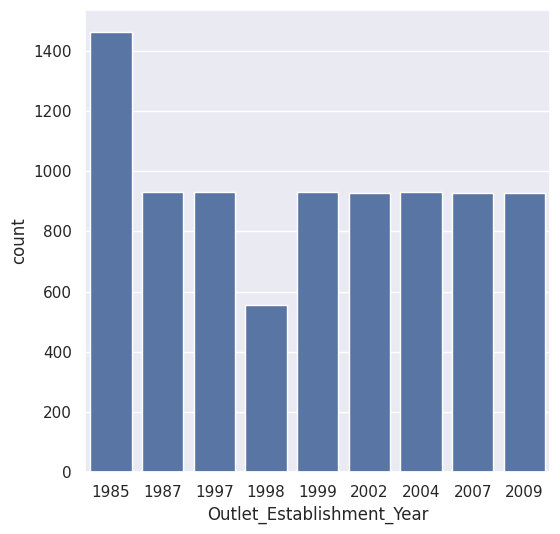

In [ ]:
# Outlet_Establishment_Year column
plt.figure(figsize=(6,6))
sns.countplot(x='Outlet_Establishment_Year', data=big_mart_data)
plt.show()

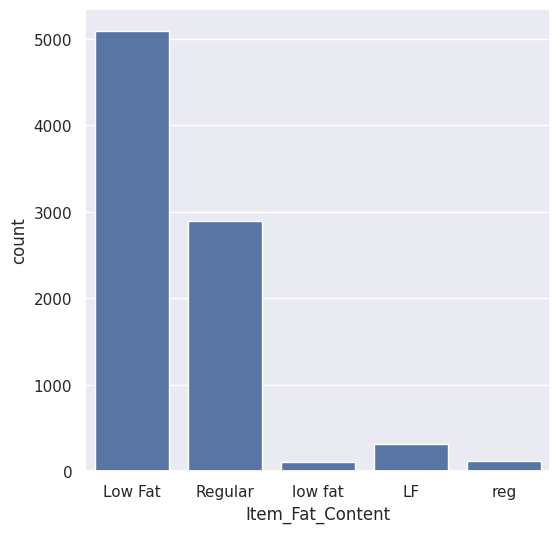

In [ ]:
# Item_Fat_Content column
plt.figure(figsize=(6,6))
sns.countplot(x='Item_Fat_Content', data=big_mart_data)
plt.show()

In [ ]:
"""Data Pre-Processing"""

big_mart_data.replace({'Item_Fat_Content': {'low fat':'Low Fat','LF':'Low Fat', 'reg':'Regular'}}, inplace=True)

big_mart_data['Item_Fat_Content'].value_counts()

,count
Item_Fat_Content,
Low Fat,5517
Regular,3006


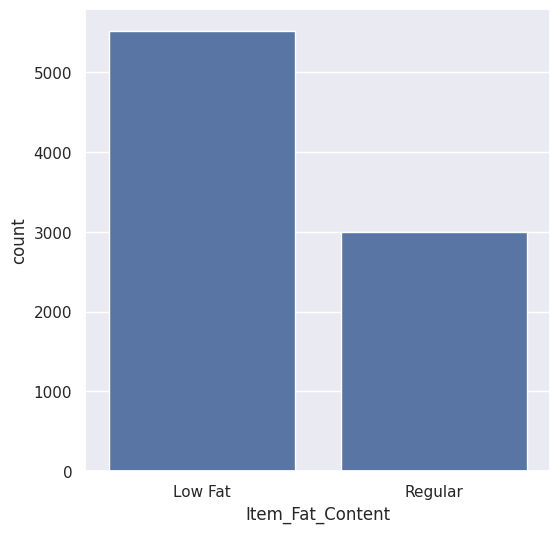

In [ ]:
# Item_Fat_Content column
plt.figure(figsize=(6,6))
sns.countplot(x='Item_Fat_Content', data=big_mart_data)
plt.show()

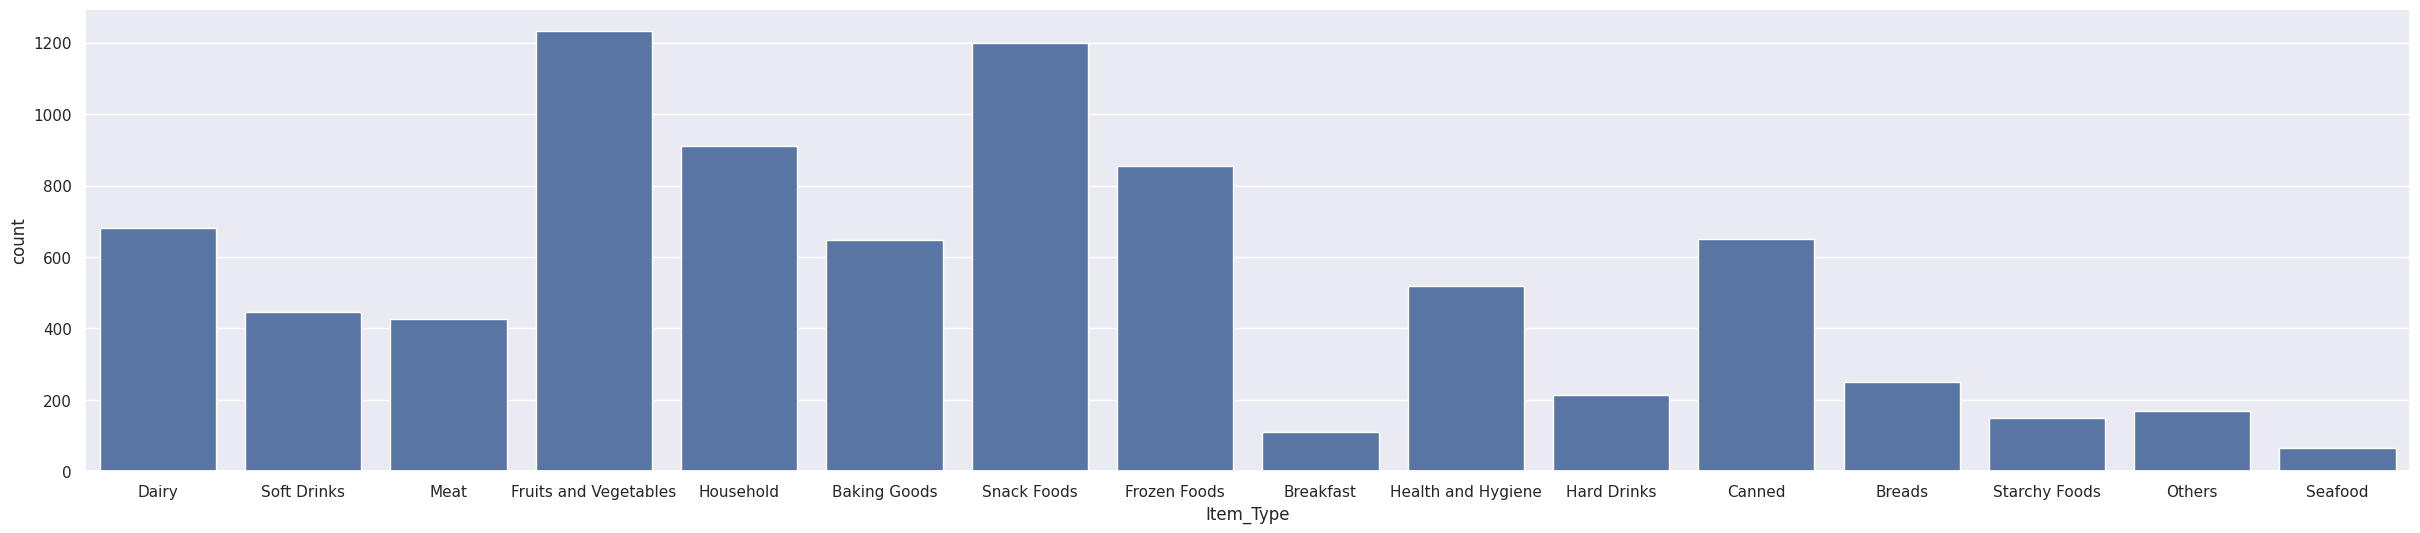

In [ ]:
# Item_Type column
plt.figure(figsize=(30,6))
sns.countplot(x='Item_Type', data=big_mart_data)
plt.show()

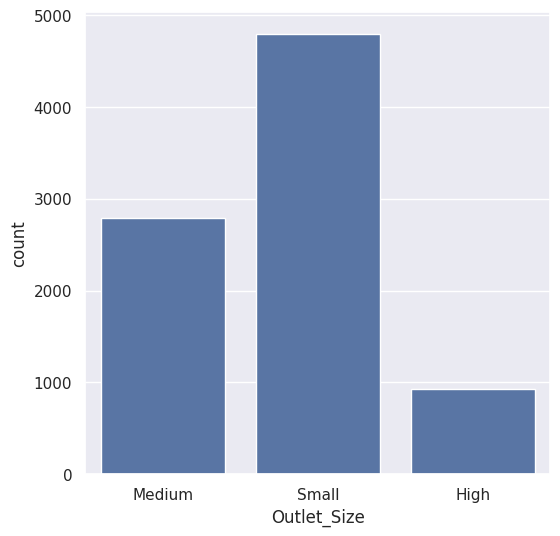

In [ ]:
# Outlet_Size column
plt.figure(figsize=(6,6))
sns.countplot(x='Outlet_Size', data=big_mart_data)
plt.show()

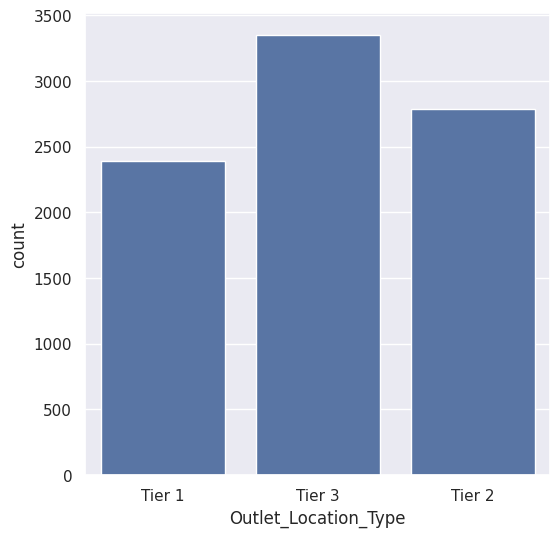

In [ ]:
# Outlet_Location_Type
plt.figure(figsize=(6,6))
sns.countplot(x='Outlet_Location_Type', data=big_mart_data)
plt.show()

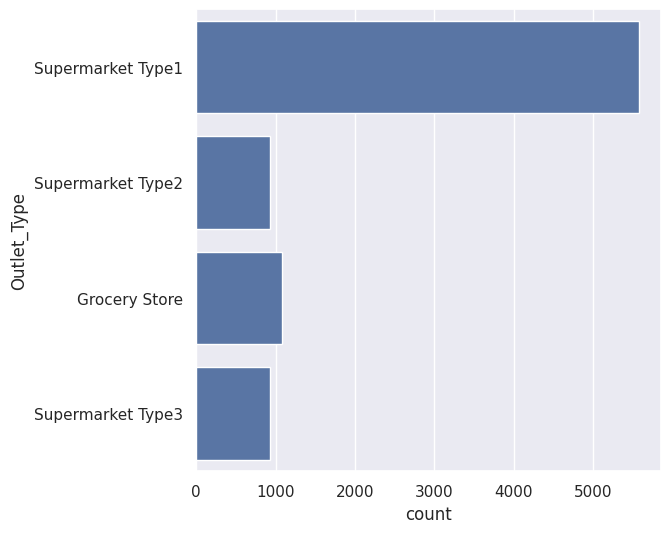

In [ ]:
# Outlet_Type
plt.figure(figsize=(6,6))
sns.countplot(y='Outlet_Type', data=big_mart_data)
plt.show()

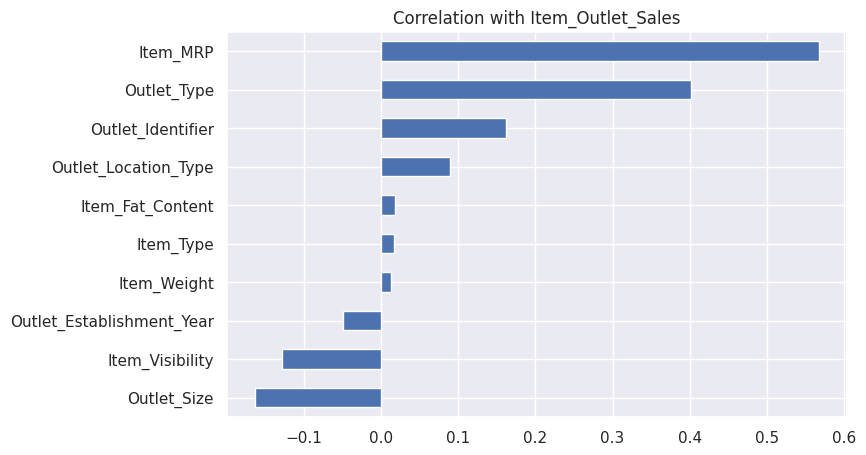

In [ ]:

# Simplify dataframe by dropping identifier and encoding objects
df = big_mart_data.drop(columns='Item_Identifier')
for col in df.select_dtypes('object'):
    df[col] = df[col].astype('category').cat.codes

# Calculate correlation with target and plot
corr = df.corr()['Item_Outlet_Sales'].drop('Item_Outlet_Sales').sort_values()

plt.figure(figsize=(8, 5))
corr.plot(kind='barh')
plt.title('Correlation with Item_Outlet_Sales')
plt.show()

In [ ]:

"""Feature Engineering

Only 3 things are needed:
- Item_MRP (price)
- Outlet_Identifier (which store)
- Item_Identifier number (last 2 digits, e.g. FDA15 --> 15)
"""

# splitting features and target
X = big_mart_data.drop(columns='Item_Outlet_Sales')
Y = big_mart_data['Item_Outlet_Sales']

# joining train and test features so both get exactly the same encoding
all_data = pd.concat([X, test_data], ignore_index=True)

# 2. Price effect for each outlet (outlet x log of MRP)
mrp = all_data['Item_MRP'].values
outlet_price = outlet * np.log(mrp)[:, None]
print(outlet_price)

# 3. Item number as a plain number (scaled)
item_number = all_data['Item_Identifier'].str[3:].astype(int).values.reshape(-1, 1)
item_curve = item_number

# final feature matrix
features = np.hstack([outlet, outlet_price, item_curve])

[[0.         0.         0.         ... 0.         0.         5.52069743]
 [0.         0.         0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         4.95313329]
 ...
 [0.         0.         0.         ... 4.77696992 0.         0.        ]
 [0.         0.         5.36887741 ... 0.         0.         0.        ]
 [0.         0.         0.         ... 4.37947338 0.         0.        ]]


In [ ]:
# separating train rows and test rows
X_all = features[:len(X)]
X_final_test = features[len(X):]

"""Splitting the data into Training data & Testing Data"""

X_train, X_test, Y_train, Y_test = train_test_split(X_all, Y, test_size=0.2, random_state=2)

print(X_all.shape, X_train.shape, X_test.shape)

(8523, 21) (6818, 21) (1705, 21)


In [ ]:
#Machine Learning Model Training

regressor = GammaRegressor(alpha=0.00001, max_iter=5000)

regressor.fit(X_train, Y_train)

# prediction on test data
test_data_prediction = regressor.predict(X_test)

# R squared Value
r2_test = metrics.r2_score(Y_test, test_data_prediction)
print('R Squared value = ', r2_test)

# RMSE
rmse = np.sqrt(metrics.mean_squared_error(Y_test, test_data_prediction))
print('RMSE = ', rmse)

#Final Predictions on Test.csv

# retraining on the full training data
regressor.fit(X_all, Y)

final_test_predictions = regressor.predict(X_final_test)


R Squared value =  0.6126424057114278
R Squared value =  0.5903656206086974
RMSE =  1124.531872894633


In [ ]:
# creating the submission file
submission = pd.DataFrame({
    "Item_Identifier":   test_data["Item_Identifier"],
    "Outlet_Identifier": test_data["Outlet_Identifier"],
    "Item_Outlet_Sales": final_test_predictions,
})

submission.to_csv("submission.csv", index=False)
print(submission.head())
print("Saved submission.csv", submission.shape)

  Item_Identifier Outlet_Identifier  Item_Outlet_Sales
0           FDW58            OUT049        1829.115227
1           FDW14            OUT017        1415.619707
2           NCN55            OUT010         599.901297
3           FDQ58            OUT017        2666.062819
4           FDY38            OUT027        6186.028880
Saved submission.csv (5681, 3)
